In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Leitura do CSV
url = 'https://raw.githubusercontent.com/kyubaan/analise-clusterizacao-cd/refs/heads/main/Dataset.csv'
df = pd.read_csv(url, decimal=',', encoding='utf-8')

# Renomeando colunas, se necessário
df.columns = ['latitude', 'longitude', 'price']

print(df.head())
print(df.info())
print(df.describe())

UnicodeEncodeError: 'ascii' codec can't encode characters in position 65-66: ordinal not in range(128)

In [18]:
# Selecionando apenas latitude e longitude para clusterizar
X = df[['latitude', 'longitude']].values

# Padronização
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

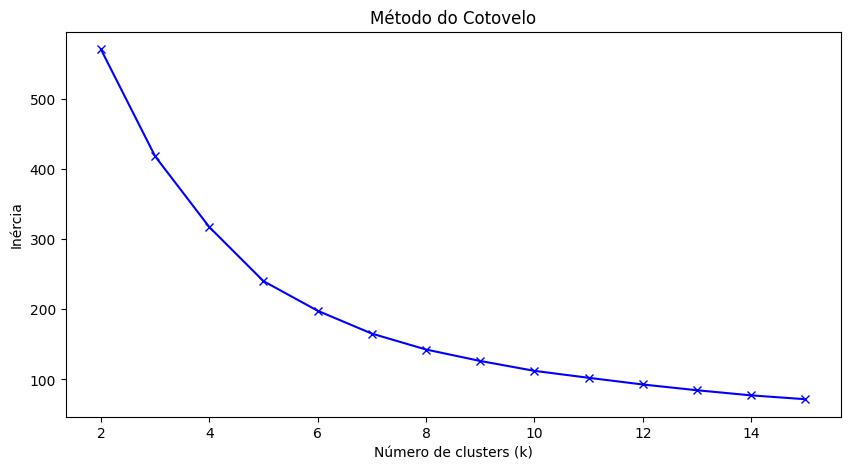

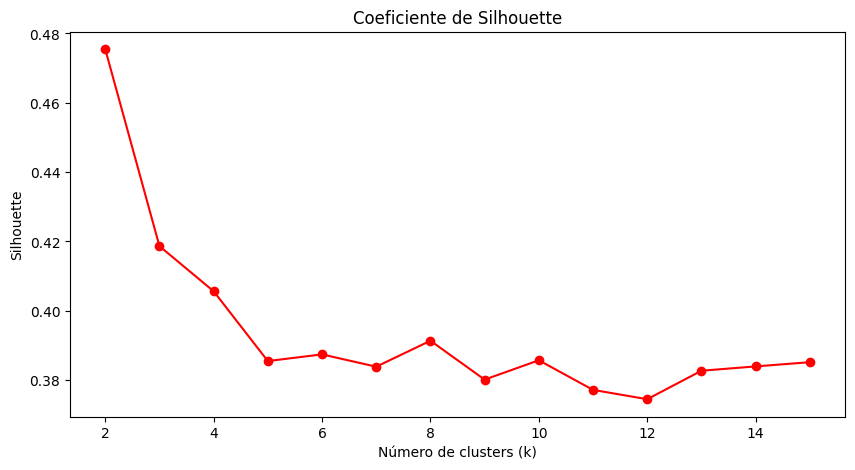

Melhor k pelo Silhouette: 2
Silhouette score: 0.4754


In [19]:
inertias = []
silhouettes = []
K = range(2, 16)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

# Gráfico do cotovelo
plt.figure(figsize=(10, 5))
plt.plot(K, inertias, 'bx-')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia')
plt.title('Método do Cotovelo')
plt.show()

# Gráfico do Silhouette
plt.figure(figsize=(10, 5))
plt.plot(K, silhouettes, 'ro-')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette')
plt.title('Coeficiente de Silhouette')
plt.show()

# Melhor k pelo maior Silhouette
best_k = K[np.argmax(silhouettes)]
print(f'Melhor k pelo Silhouette: {best_k}')
print(f'Silhouette score: {max(silhouettes):.4f}')

In [4]:
# Ajuste final com o melhor k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Recuperando os centróides no espaço original
centroids_scaled = kmeans.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

centroids_df = pd.DataFrame(centroids, columns=['latitude_centro', 'longitude_centro'])
centroids_df['cluster'] = range(best_k)

# Resumo por cluster
resumo = df.groupby('cluster').agg(
    total_entregas=('price', 'sum'),
    qtd_entregas=('price', 'count'),
    ticket_medio=('price', 'mean')
).reset_index()

resumo = resumo.merge(centroids_df, on='cluster')

print(resumo)

   cluster  total_entregas  qtd_entregas  ticket_medio  latitude_centro  \
0        0        22174.73           358     61.940587       -21.318929   
1        1        19009.08           295     64.437559       -23.161016   

   longitude_centro  
0        -49.770919  
1        -47.258755  


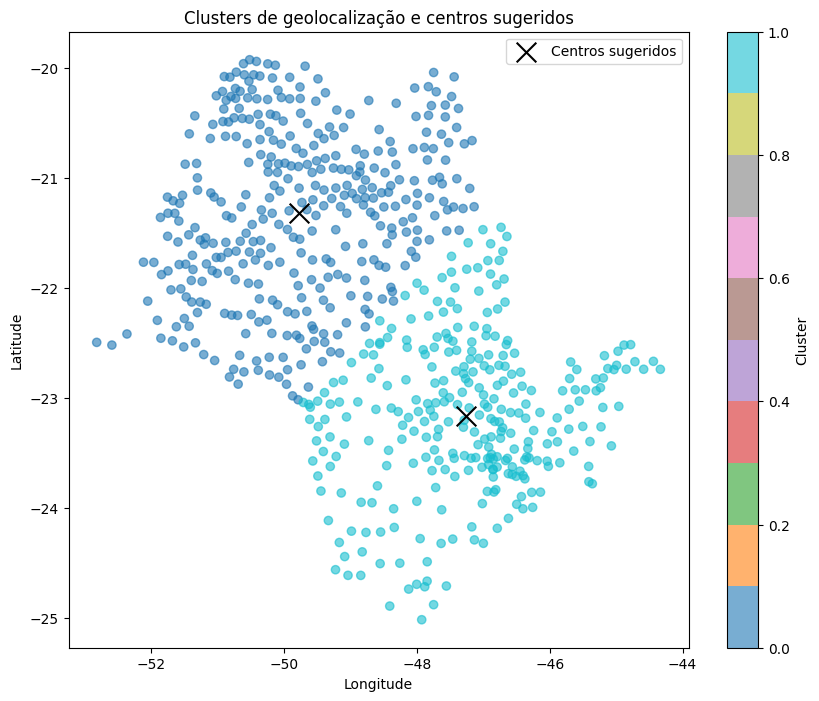

In [5]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['cluster'],
    cmap='tab10',
    alpha=0.6
)

plt.scatter(
    centroids_df['longitude_centro'],
    centroids_df['latitude_centro'],
    c='black',
    marker='x',
    s=200,
    label='Centros sugeridos'
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Clusters de geolocalização e centros sugeridos')
plt.legend()
plt.colorbar(scatter, label='Cluster')
plt.show()

In [6]:
df.to_csv('entregas_com_clusters.csv', index=False)
resumo.to_csv('resumo_centros.csv', index=False)